# Chapter 6: Advanced Logistic Regression and Extensions

This notebook covers Chapter 6 of *scikit-learn Cookbook* (3rd Edition, Packt). Logistic regression is one of the most widely used classification models: it is fast, interpretable, and produces probabilities. This chapter goes beyond the basics.

**Topics covered:**
- Binary logistic regression and the sigmoid function
- Interpreting coefficients as odds ratios
- Probabilities and decision thresholds
- Evaluation: confusion matrix, precision, recall, ROC curve, AUC
- Regularization (L1 vs. L2) and choosing `C` with `LogisticRegressionCV`
- Handling imbalanced classes with `class_weight`
- Multiclass classification: multinomial (softmax) and One-vs-Rest

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_wine, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score,
                             RocCurveDisplay, PrecisionRecallDisplay,
                             precision_score, recall_score, f1_score)

## 1. Binary Logistic Regression

Logistic regression computes a linear score $z = b + \mathbf{w}^T\mathbf{x}$ and converts it into a probability with the **sigmoid** function:

$$P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

The model is trained by minimizing the **log loss** (cross-entropy):

$$-\frac{1}{n}\sum_i \left[ y_i \log p_i + (1 - y_i)\log(1 - p_i) \right]$$

The **breast cancer** dataset is used: 569 tumors, 30 features, target 0 = malignant and 1 = benign.

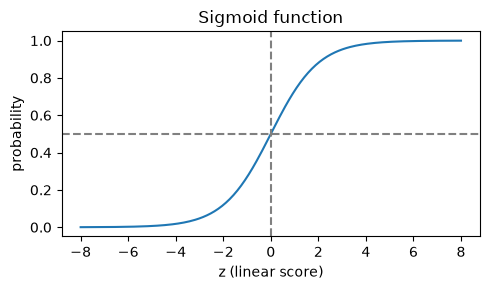

In [8]:
z = np.linspace(-8, 8, 200)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(z, 1 / (1 + np.exp(-z)))
ax.axhline(0.5, color='grey', linestyle='--')
ax.axvline(0, color='grey', linestyle='--')
ax.set_xlabel('z (linear score)')
ax.set_ylabel('probability')
ax.set_title('Sigmoid function')
plt.tight_layout()
plt.show()

In [9]:
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
feature_names = cancer.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
print(f'Test accuracy: {logreg.score(X_test, y_test):.3f}')

Test accuracy: 0.986


The sigmoid maps any score to a probability between 0 and 1, with a score of 0 giving exactly 0.5. Even with default settings, scaled logistic regression classifies tumors very accurately.

## 2. Interpreting Coefficients: Odds Ratios

Logistic regression is linear in the **log odds**:

$$\log \frac{p}{1-p} = b + \sum_j w_j x_j$$

So $e^{w_j}$ is the **odds ratio**: how the odds of the positive class (benign) are multiplied when feature $j$ increases by one unit (here, one standard deviation, since the data is standardized). Values above 1 increase the odds; values below 1 decrease them.

In [10]:
coefs = pd.DataFrame({
    'coefficient': logreg[-1].coef_[0],
    'odds_ratio': np.exp(logreg[-1].coef_[0]),
}, index=feature_names).sort_values('coefficient')

coefs.round(3).head(8)

,coefficient,odds_ratio
worst texture,-1.250,0.286
radius error,-1.070,0.343
worst symmetry,-0.957,0.384
worst concave points,-0.942,0.390
area error,-0.941,0.390
worst area,-0.926,0.396
worst radius,-0.917,0.400
worst concavity,-0.797,0.451


The features with the most negative coefficients (and odds ratios well below 1) reduce the odds of a tumor being benign, meaning larger values of those measurements point toward malignancy. This kind of interpretation is one of the main reasons logistic regression is popular in fields such as medicine.

## 3. Probabilities and the Decision Threshold

`predict_proba()` returns probabilities, and `predict()` assigns the positive class when the probability is at least **0.5**. That threshold is not always the best choice: in medical screening, missing a malignant tumor is much worse than a false alarm, so a different threshold may be preferred.

In [11]:
proba_benign = logreg.predict_proba(X_test)[:, 1]
print('First 5 predicted P(benign):', proba_benign[:5].round(3))

for threshold in [0.3, 0.5, 0.7, 0.9]:
    pred = (proba_benign >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f'threshold={threshold}: malignant tumors wrongly called benign = {fp:>2}, '
          f'benign tumors flagged as malignant = {fn:>2}')

First 5 predicted P(benign): [0.969 0.    0.559 0.939 0.175]
threshold=0.3: malignant tumors wrongly called benign =  3, benign tumors flagged as malignant =  0
threshold=0.5: malignant tumors wrongly called benign =  1, benign tumors flagged as malignant =  1
threshold=0.7: malignant tumors wrongly called benign =  1, benign tumors flagged as malignant =  6
threshold=0.9: malignant tumors wrongly called benign =  0, benign tumors flagged as malignant = 11


Raising the threshold for calling a tumor benign means the model needs more confidence before saying "benign". This reduces the number of malignant tumors that are missed, at the cost of flagging more benign tumors for further checks. The right threshold depends on the cost of each type of error, not only on accuracy.

## 4. Evaluating a Classifier

Accuracy alone can hide important errors. Common metrics:
- **Confusion matrix**: counts of true/false positives and negatives.
- **Precision**: of the predicted positives, how many are correct, $\frac{TP}{TP + FP}$.
- **Recall (sensitivity)**: of the actual positives, how many were found, $\frac{TP}{TP + FN}$.
- **F1-score**: the harmonic mean of precision and recall.
- **ROC curve**: true positive rate vs. false positive rate across all thresholds; the **AUC** summarizes it (1.0 = perfect, 0.5 = random).
- **Precision-recall curve**: more informative than ROC when the positive class is rare.

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



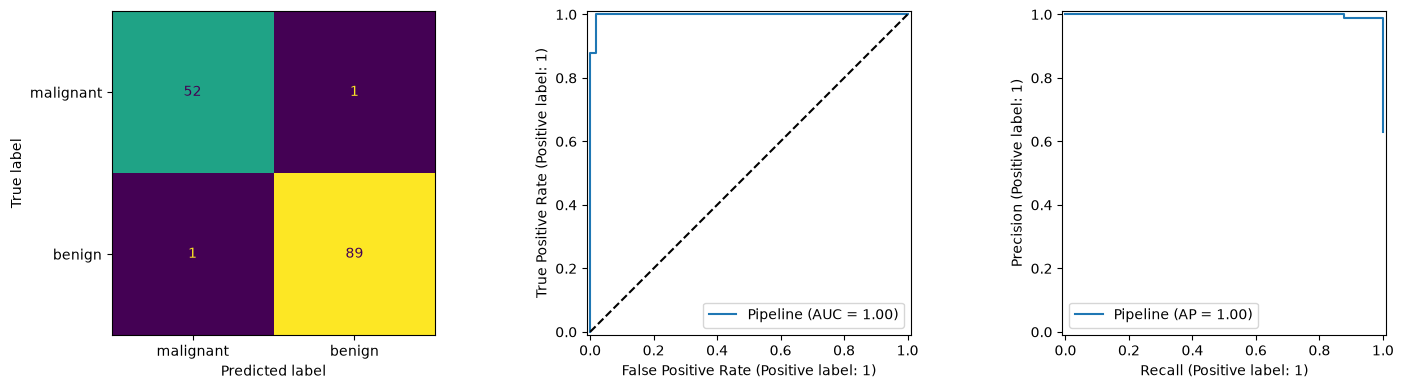

ROC AUC: 0.998


In [6]:
pred = logreg.predict(X_test)
print(classification_report(y_test, pred, target_names=cancer.target_names))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=cancer.target_names,
                                        ax=axes[0], colorbar=False)
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--')
PrecisionRecallDisplay.from_estimator(logreg, X_test, y_test, ax=axes[2])
plt.tight_layout()
plt.show()

print(f'ROC AUC: {roc_auc_score(y_test, proba_benign):.3f}')

The confusion matrix shows only a few errors, and both precision and recall are high for each class. The ROC curve hugs the top-left corner with an AUC close to 1, meaning the model ranks malignant and benign tumors almost perfectly across all thresholds.

## 5. Regularization: L1 vs. L2 and Choosing C

Logistic regression in scikit-learn is regularized by default. The parameter `C` is the **inverse** of the regularization strength: small `C` means strong regularization, large `C` means weak regularization.
- **L2** (default): shrinks all coefficients smoothly.
- **L1**: can set coefficients to exactly zero, performing feature selection (requires a solver such as `liblinear` or `saga`).

`LogisticRegressionCV` chooses `C` automatically with cross-validation.

In [12]:
for C in [0.01, 0.1, 1, 10]:
    l1 = make_pipeline(StandardScaler(),
                       LogisticRegression(penalty='l1', C=C, solver='liblinear', max_iter=5000))
    l1.fit(X_train, y_train)
    n_used = int((l1[-1].coef_ != 0).sum())
    print(f'L1, C={C:>5}: test accuracy = {l1.score(X_test, y_test):.3f}, '
          f'features used = {n_used:>2} of 30')

L1, C= 0.01: test accuracy = 0.909, features used =  4 of 30
L1, C=  0.1: test accuracy = 0.972, features used =  7 of 30
L1, C=    1: test accuracy = 0.993, features used = 16 of 30
L1, C=   10: test accuracy = 0.958, features used = 22 of 30


In [13]:
logreg_cv = make_pipeline(StandardScaler(),
                          LogisticRegressionCV(Cs=20, cv=5, max_iter=5000))
logreg_cv.fit(X_train, y_train)
print('Best C:', round(logreg_cv[-1].C_[0], 4))
print(f'Test accuracy: {logreg_cv.score(X_test, y_test):.3f}')

Best C: 0.0886
Test accuracy: 0.979


With strong L1 regularization (small `C`), the model uses only a handful of the 30 features while keeping high accuracy, which makes it simpler and easier to explain. `LogisticRegressionCV` searches over 20 values of `C` and picks the one with the best cross-validated performance.

## 6. Imbalanced Classes

When one class is rare, a model can reach high accuracy by mostly predicting the majority class while missing the cases that matter. Setting `class_weight='balanced'` gives errors on the rare class more weight:

$$w_c = \frac{n}{C \cdot n_c}$$

where $n_c$ is the number of samples in class $c$.

In [14]:
X_imb, y_imb = make_classification(n_samples=3000, n_features=10, n_informative=4,
                                   weights=[0.95, 0.05], random_state=42)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_imb, y_imb, test_size=0.3,
                                              random_state=42, stratify=y_imb)
print('Share of rare class:', yi_tr.mean().round(3))

for cw in [None, 'balanced']:
    m = make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw, max_iter=1000))
    m.fit(Xi_tr, yi_tr)
    p = m.predict(Xi_te)
    print(f'class_weight={str(cw):>8}: accuracy={m.score(Xi_te, yi_te):.3f}, '
          f'recall={recall_score(yi_te, p):.3f}, precision={precision_score(yi_te, p):.3f}, '
          f'F1={f1_score(yi_te, p):.3f}')

Share of rare class: 0.054
class_weight=    None: accuracy=0.951, recall=0.102, precision=1.000, F1=0.185
class_weight=balanced: accuracy=0.659, recall=0.592, precision=0.092, F1=0.159


Without class weights, accuracy looks high but recall on the rare class is low: many rare cases are missed. With `class_weight='balanced'`, recall rises sharply, at the cost of lower precision and slightly lower accuracy. For problems such as fraud or disease detection, this trade-off is usually worth it.

## 7. Multiclass Logistic Regression

Logistic regression extends to more than two classes in two ways:
- **Multinomial (softmax)**: one model that gives a probability for every class at once, $P(y=k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_j e^{z_j}}$. This is the default for multiclass problems in scikit-learn.
- **One-vs-Rest (OvR)**: one binary model per class ("this class vs. all others"), wrapped with `OneVsRestClassifier`.

The **wine** dataset (3 cultivars) is used.

In [15]:
wine = load_wine()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.25,
                                              random_state=42, stratify=wine.target)

softmax = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
ovr = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))

for name, m in [('Multinomial (softmax)', softmax), ('One-vs-Rest', ovr)]:
    m.fit(Xw_tr, yw_tr)
    auc = roc_auc_score(yw_te, m.predict_proba(Xw_te), multi_class='ovr')
    print(f'{name:>22}: accuracy = {m.score(Xw_te, yw_te):.3f}, macro ROC AUC = {auc:.3f}')

print('\nProbabilities for the first test wine:', softmax.predict_proba(Xw_te[:1]).round(3))

 Multinomial (softmax): accuracy = 1.000, macro ROC AUC = 1.000
           One-vs-Rest: accuracy = 1.000, macro ROC AUC = 1.000

Probabilities for the first test wine: [[0.926 0.072 0.002]]


Both strategies classify the wines very well. The softmax model gives a probability for each of the 3 classes that sums to 1. For multiclass problems, the ROC AUC is computed by treating each class as "one vs. rest" and averaging.

## Chapter Summary

- Logistic regression turns a linear score into a probability with the **sigmoid** function and is trained by minimizing **log loss**.
- Coefficients are interpreted through **odds ratios** ($e^{w}$), which makes the model highly explainable.
- The default **0.5 threshold** can be changed to reflect the cost of different errors.
- Evaluate with the **confusion matrix, precision, recall, F1, ROC AUC**, and the **precision-recall curve**, not accuracy alone.
- `C` controls regularization strength; **L1** produces sparse models with fewer features, **L2** shrinks all coefficients. `LogisticRegressionCV` picks `C` automatically.
- `class_weight='balanced'` improves recall on rare classes in **imbalanced** data.
- Multiclass problems use **softmax** (default) or **One-vs-Rest**.